In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import stats
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import KFold, LeaveOneOut, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_val_score, cross_validate, train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
N_JOBS = 1

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

In [2]:
cancer_data = load_breast_cancer(as_frame=True)
cancer_features = cancer_data.data
cancer_target = 1 - cancer_data.target
cancer_target.name = "malignant"
cancer_indices = np.arange(len(cancer_features))

cancer_split = train_test_split(cancer_indices, test_size=0.2, stratify=cancer_target, random_state=RANDOM_STATE)
development_indices = cancer_split[0]
final_test_indices = cancer_split[1]

X_dev = cancer_features.iloc[development_indices].reset_index(drop=True)
y_dev = cancer_target.iloc[development_indices].reset_index(drop=True)
X_final_test = cancer_features.iloc[final_test_indices].reset_index(drop=True)
y_final_test = cancer_target.iloc[final_test_indices].reset_index(drop=True)

In [3]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
     ("classifier", LogisticRegression(C=1.0, solver="liblinear", max_iter=3000, random_state=RANDOM_STATE))
])
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])
classification_models = {"Логистическая регрессия": logistic_model, "kNN, k=7": knn_model}

### Одного test недостаточно для уверенного сравнения!

In [4]:
holdout_records = []
holdout_seeds = range(40)
development_positions = np.arange(len(X_dev))

for split_seed in holdout_seeds:
    holdout_split = train_test_split(development_positions, test_size=0.25, stratify=y_dev, random_state=split_seed)
    holdout_train_indices = holdout_split[0]
    holdout_valid_indices = holdout_split[1]
    for model_name in classification_models:
        fitted_model = clone(classification_models[model_name])
        fitted_model.fit(X_dev.iloc[holdout_train_indices], y_dev.iloc[holdout_train_indices])
        valid_probabilities = fitted_model.predict_proba(X_dev.iloc[holdout_valid_indices])[:, 1]
        holdout_auc = roc_auc_score(y_dev.iloc[holdout_valid_indices], valid_probabilities)
        holdout_records.append({"split_seed": split_seed, "model": model_name, "roc_auc": holdout_auc})

holdout_results = pd.DataFrame(holdout_records)
holdout_paired = holdout_results.pivot(index="split_seed", columns="model", values="roc_auc")
holdout_paired["difference_knn_minus_logistic"] = holdout_paired["kNN, k=7"] - holdout_paired["Логистическая регрессия"]

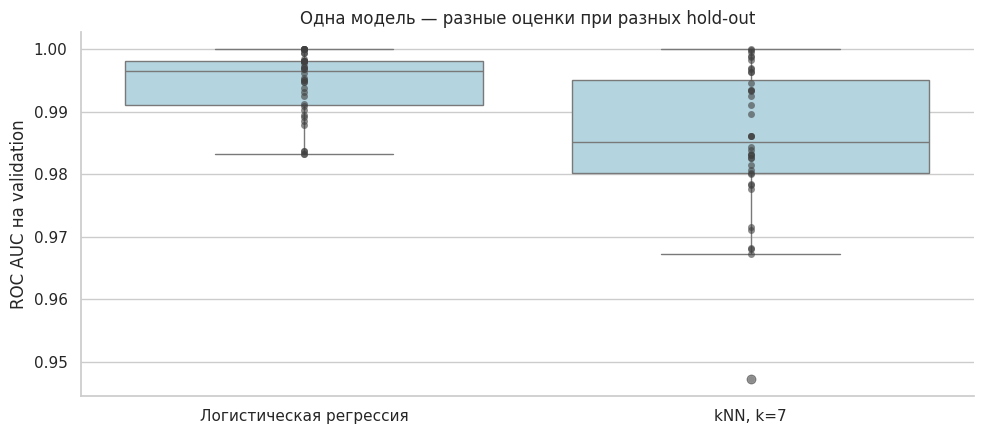

In [5]:
figure = plt.figure(figsize=(10, 4.5))
axis = figure.add_subplot(111)
sns.boxplot(data=holdout_results, x="model", y="roc_auc", color="lightblue", ax=axis)
sns.stripplot(data=holdout_results, x="model", y="roc_auc", color="0.25", alpha=0.6, jitter=False, ax=axis)
axis.set(title="Одна модель — разные оценки при разных hold-out", xlabel="", ylabel="ROC AUC на validation")
plt.tight_layout()
plt.show()

На трудном разбиении обе модели могут получить низкое качество. Поэтому вопрос "кто лучше" удобнее изучать по разнице на одном и том же validation, а не только по двум отдельным распределениям.

В следующем графике положительное значение означает преимущество kNN, отрицательное — логистической регрессии.

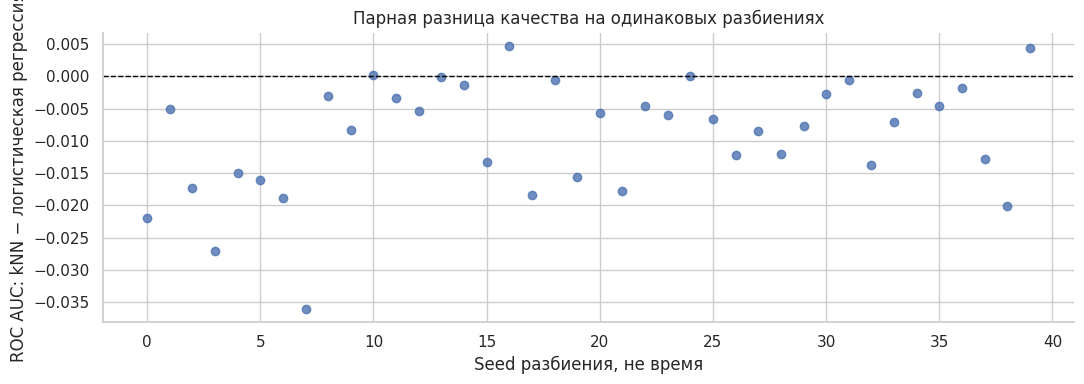

In [6]:
figure = plt.figure(figsize=(11, 4))
axis = figure.add_subplot(111)
axis.scatter(holdout_paired.index, holdout_paired["difference_knn_minus_logistic"], alpha=0.8)
axis.axhline(0, color="black", linestyle="--", linewidth=1)
axis.set(title="Парная разница качества на одинаковых разбиениях", xlabel="Seed разбиения, не время", ylabel="ROC AUC: kNN − логистическая регрессия")
plt.tight_layout()
plt.show()

### Размер test тоже влияет!

In [7]:
validation_size_records = []

for validation_fraction in [0.1, 0.25, 0.4]:
    for split_seed in range(25):
        size_split = train_test_split(development_positions, test_size=validation_fraction, stratify=y_dev, random_state=split_seed)
        size_train_indices = size_split[0]
        size_valid_indices = size_split[1]
        size_model = clone(logistic_model)
        size_model.fit(X_dev.iloc[size_train_indices], y_dev.iloc[size_train_indices])
        size_probabilities = size_model.predict_proba(X_dev.iloc[size_valid_indices])[:, 1]

        validation_size_records.append({
            "validation_fraction": str(validation_fraction),
            "roc_auc": roc_auc_score(y_dev.iloc[size_valid_indices], size_probabilities),
            "n_train": len(size_train_indices), "n_valid": len(size_valid_indices)
        })

validation_size_results = pd.DataFrame(validation_size_records)

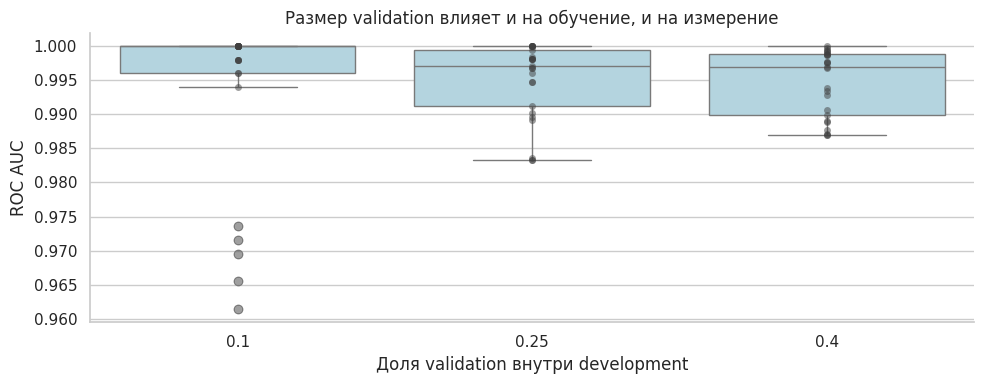

In [8]:
figure = plt.figure(figsize=(10, 4))
axis = figure.add_subplot(111)
sns.boxplot(data=validation_size_results, x="validation_fraction", y="roc_auc", color="lightblue", ax=axis)
sns.stripplot(data=validation_size_results, x="validation_fraction", y="roc_auc", color="0.25", alpha=0.5, jitter=False, ax=axis)
axis.set(title="Размер validation влияет и на обучение, и на измерение", xlabel="Доля validation внутри development", ylabel="ROC AUC")
plt.tight_layout()
plt.show()

Фиксированный hold-out может быть вполне подходящей проверкой, но одно число не показывает чувствительность результата к составу данных

### Схема train-validation-test

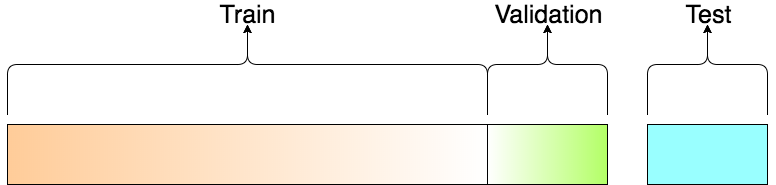

Потенциальные проблемы подхода с выделением одной выборкидля оценки:

*   Нарушение баланса целевой переменной / предположения о независимости объектов
*   Недостаточная емкость модели и пессимистичное смещение оценки качества
*   Точечная оценка



## Кросс-валидация

Процесс обучения модели можно представить в следующем виде:

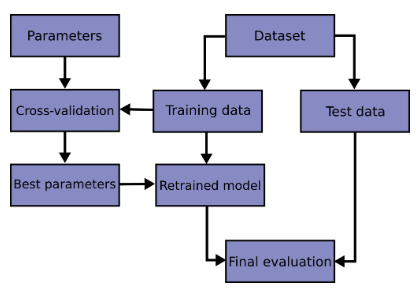

При обучении модели мы измеряем качество на тестовых данных, однако подбор моделей / гиперпараметров стоит проводить на валидационном наборе данных, а уже после финально оценивать качество на тесте.

### Стратификация

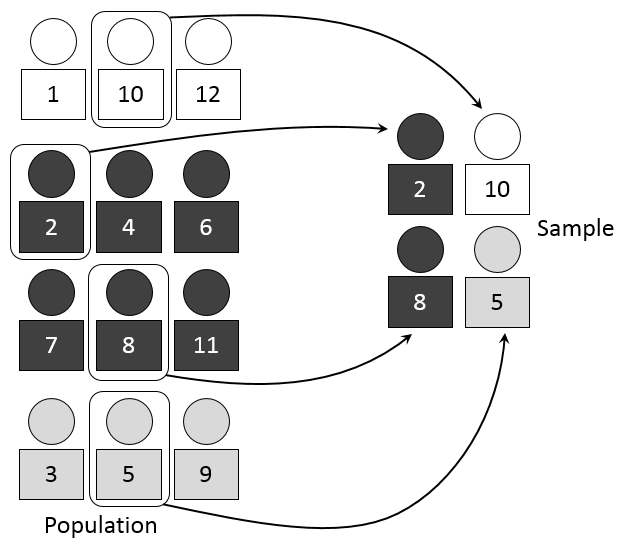

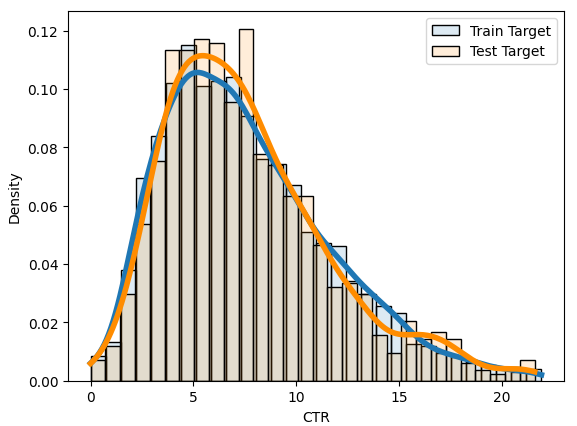

In [9]:
X, y = load_breast_cancer(return_X_y=True, as_frame=True)

y = 1 - y
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2023, test_size=0.15, stratify=y) # разбиение со стратификацией

In [10]:
y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)

(target
 0    0.6273
 1    0.3727
 Name: proportion, dtype: float64,
 target
 0    0.6279
 1    0.3721
 Name: proportion, dtype: float64)

### K-Fold


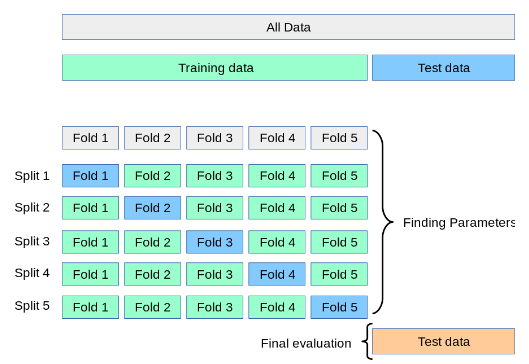

In [11]:
classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
classification_splits = list(classification_cv.split(X_dev, y_dev))
fold_composition_records = []

for fold_index in range(len(classification_splits)):
    fold_train_indices = classification_splits[fold_index][0]
    fold_valid_indices = classification_splits[fold_index][1]
    fold_composition_records.append({
        "fold": fold_index + 1,
        "n_train": len(fold_train_indices),
        "n_valid": len(fold_valid_indices),
        "positive_train": int(y_dev.iloc[fold_train_indices].sum()),
        "positive_valid": int(y_dev.iloc[fold_valid_indices].sum()),
        "positive_fraction_valid": y_dev.iloc[fold_valid_indices].mean()
    })

fold_composition = pd.DataFrame(fold_composition_records)

#### Визуальная схема фолдов

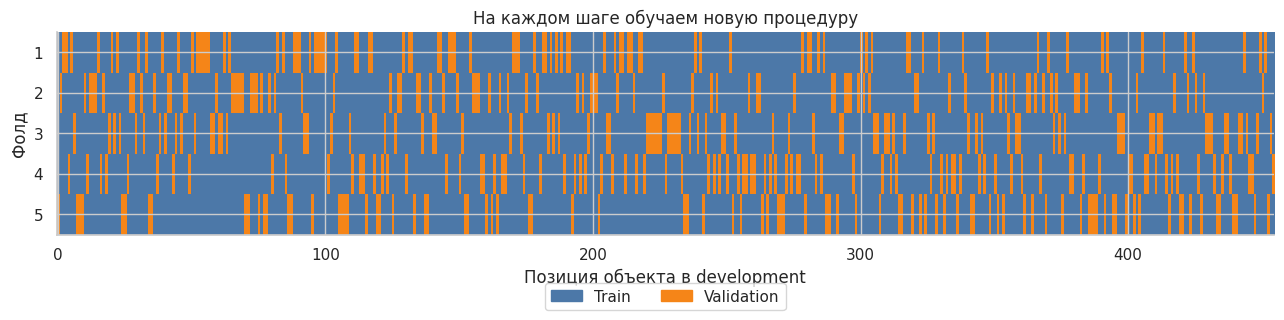

In [12]:
classification_split_matrix = np.zeros((len(classification_splits), len(X_dev)), dtype=int)

for fold_index in range(len(classification_splits)):
    classification_split_matrix[fold_index, classification_splits[fold_index][1]] = 1

figure = plt.figure(figsize=(13, 3.5))
axis = figure.add_subplot(111)
axis.imshow(classification_split_matrix, aspect="auto", interpolation="nearest", cmap=ListedColormap(["#4C78A8", "#F58518"]), vmin=0, vmax=1)
axis.set_yticks(np.arange(5))
axis.set_yticklabels(np.arange(1, 6))
axis.set(title="На каждом шаге обучаем новую процедуру", xlabel="Позиция объекта в development", ylabel="Фолд")
axis.legend(handles=[Patch(color="#4C78A8", label="Train"), Patch(color="#F58518", label="Validation")], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

#### Делаем KFold руками

In [13]:
manual_cv_records = []
manual_oof_probabilities = np.full(len(X_dev), np.nan)
manual_oof_predictions = np.full(len(X_dev), -1, dtype=int)
manual_validation_counts = np.zeros(len(X_dev), dtype=int)

for fold_index in range(len(classification_splits)):
    fold_train_indices = classification_splits[fold_index][0]
    fold_valid_indices = classification_splits[fold_index][1]
    fold_model = clone(logistic_model)
    fold_model.fit(X_dev.iloc[fold_train_indices], y_dev.iloc[fold_train_indices])
    train_probabilities = fold_model.predict_proba(X_dev.iloc[fold_train_indices])[:, 1]
    valid_probabilities = fold_model.predict_proba(X_dev.iloc[fold_valid_indices])[:, 1]
    valid_predictions = (valid_probabilities >= 0.5).astype(int)
    manual_oof_probabilities[fold_valid_indices] = valid_probabilities
    manual_oof_predictions[fold_valid_indices] = valid_predictions
    manual_validation_counts[fold_valid_indices] += 1

    manual_cv_records.append({
        "fold": fold_index + 1,
        "train_auc": roc_auc_score(y_dev.iloc[fold_train_indices], train_probabilities),
        "valid_auc": roc_auc_score(y_dev.iloc[fold_valid_indices], valid_probabilities),
        "valid_f1": f1_score(y_dev.iloc[fold_valid_indices], valid_predictions),
        "n_valid": len(fold_valid_indices)
  })

manual_cv_results = pd.DataFrame(manual_cv_records)
manual_cv_results

,fold,train_auc,valid_auc,valid_f1,n_valid
0,1,0.9981,0.9954,0.9375,91
1,2,0.9969,0.9990,0.9565,91
2,3,0.9969,1.0000,1.0000,91
3,4,0.9991,0.9871,0.9697,91
4,5,0.9975,0.9979,0.9565,91


#### То же самое через cross_validate

In [14]:
library_cv_results = cross_validate(
    logistic_model,
    X_dev,
    y_dev,
    cv=classification_splits,
    scoring={"auc": "roc_auc", "f1": "f1"},
    return_train_score=True,
    n_jobs=N_JOBS,
    error_score="raise"
)

cv_metric_summary = pd.DataFrame({
    "metric": ["ROC AUC", "F1"],
    "mean_validation": [library_cv_results["test_auc"].mean(), library_cv_results["test_f1"].mean()],
    "std_across_folds_not_CI": [library_cv_results["test_auc"].std(ddof=1), library_cv_results["test_f1"].std(ddof=1)]
})
cv_metric_summary

,metric,mean_validation,std_across_folds_not_CI
0,ROC AUC,0.9959,0.0052
1,F1,0.9640,0.0231


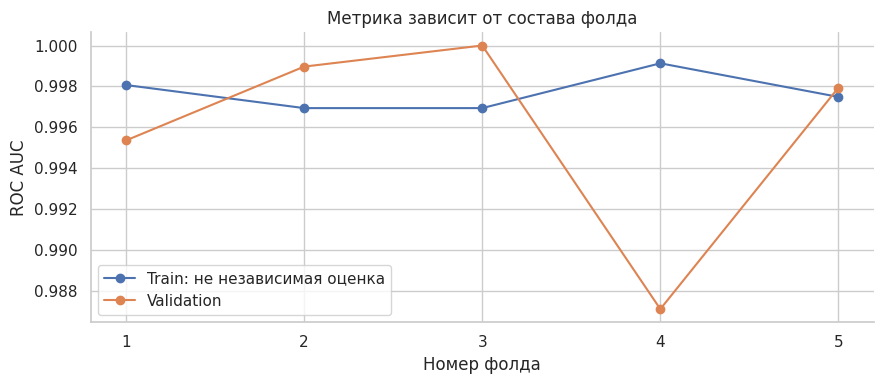

In [15]:
figure = plt.figure(figsize=(9, 4))
axis = figure.add_subplot(111)
axis.plot(manual_cv_results["fold"], manual_cv_results["train_auc"], marker="o", label="Train: не независимая оценка")
axis.plot(manual_cv_results["fold"], manual_cv_results["valid_auc"], marker="o", label="Validation")
axis.set_xticks(manual_cv_results["fold"])
axis.set(title="Метрика зависит от состава фолда", xlabel="Номер фолда", ylabel="ROC AUC")
axis.legend()
plt.tight_layout()
plt.show()

#### Сколько фолдов выбрать

Большее число фолдов означает больше обучений и больший train в каждом обучении, но меньший validation. Часто начинают с 5 или 10 фолдов, если хватает объектов каждого класса и вычислительных ресурсов.

#### Как после такой валидации получить финальную модель?

- переобучить лучшую модель на всей train части
- усреднить предсказания отдельных моделей

### Утечки - что должно находиться внутри CV

Сгенерируем много независимых шумовых признаков и независимую от них цель. На действительно новых объектах ожидаем качество около случайного уровня.

SelectKBest оставляет признаки с самой сильной наблюдаемой связью с целью.

Неправильный вариант выбирает признаки на всём наборе до CV: ответы будущих validation-объектов уже помогли выбрать столбцы. Правильный вариант повторяет отбор только на train каждого фолда. Число сохраняемых признаков фиксируем заранее и не подбираем по результату этого сравнения.

In [16]:
noise_rng = np.random.default_rng(RANDOM_STATE)
noise_features = noise_rng.normal(size=(300, 3000))
noise_target = noise_rng.integers(0, 2, size=300)
noise_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
noise_splits = list(noise_cv.split(noise_features, noise_target))

leaky_selector = SelectKBest(score_func=f_classif, k=50)
noise_features_selected_globally = leaky_selector.fit_transform(noise_features, noise_target)
noise_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE)),
])
noise_leaky_scores = cross_val_score(
    noise_classifier,
    noise_features_selected_globally,
    noise_target, cv=noise_splits,
    scoring="roc_auc",
    n_jobs=N_JOBS,
    error_score="raise",
)

noise_correct_model = Pipeline([
    ("selector", SelectKBest(score_func=f_classif, k=50)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE)),
])
noise_correct_scores = cross_val_score(noise_correct_model, noise_features, noise_target, cv=noise_splits, scoring="roc_auc", n_jobs=N_JOBS, error_score="raise")

noise_leakage_results = pd.DataFrame({"fold": np.arange(1, 6), "Отбор до CV: утечка": noise_leaky_scores, "Отбор внутри CV": noise_correct_scores})

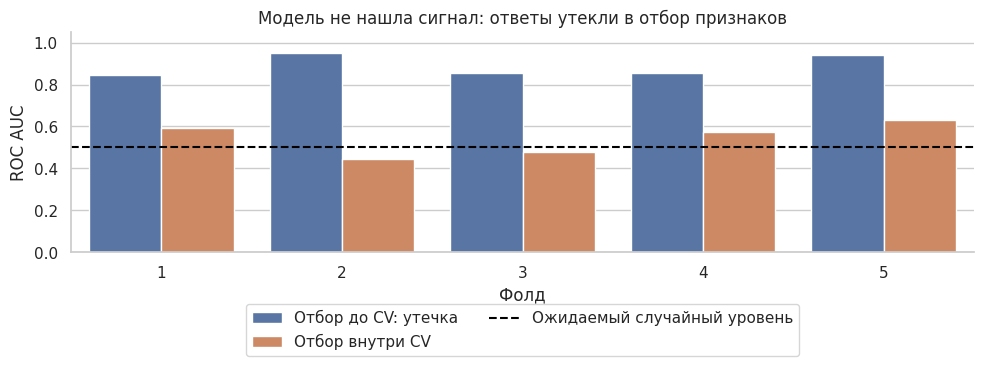

In [17]:
noise_plot_data = noise_leakage_results.melt(id_vars="fold", var_name="procedure", value_name="roc_auc")

figure = plt.figure(figsize=(10, 4))
axis = figure.add_subplot(111)
sns.barplot(data=noise_plot_data, x="fold", y="roc_auc", hue="procedure", ax=axis)
axis.axhline(0.5, color="black", linestyle="--", label="Ожидаемый случайный уровень")
axis.set(title="Модель не нашла сигнал: ответы утекли в отбор признаков", xlabel="Фолд", ylabel="ROC AUC")
axis.set_ylim(0, 1.05)
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

### Leave-one-out

Метод leave-one-out является частным случаем метода k-Fold: в нём каждый фолд состоит ровно из одного семпла.

In [18]:
loo = LeaveOneOut()
for i, (train_index, val_index) in enumerate(loo.split(X_dev)):
  train_data, train_label = X_dev.iloc[train_index], y_dev.iloc[train_index]
  val_data, val_label = X_dev.iloc[val_index], y_dev.iloc[val_index]

  log_reg = clone(logistic_model)
  log_reg.fit(train_data, train_label)
  y_pred = log_reg.predict(val_data)
  if i % 100 == 0:
    print(f'F1-score on fold {i}: {f1_score(val_label, y_pred, zero_division=0)}')

F1-score on fold 0: 1.0
F1-score on fold 100: 0.0
F1-score on fold 200: 0.0
F1-score on fold 300: 1.0
F1-score on fold 400: 1.0


Метод может быть полезен, если очень мало данных

### Time series cross-validation

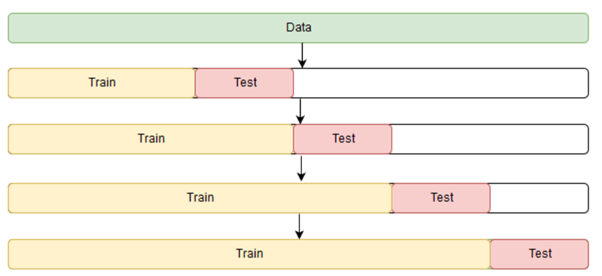

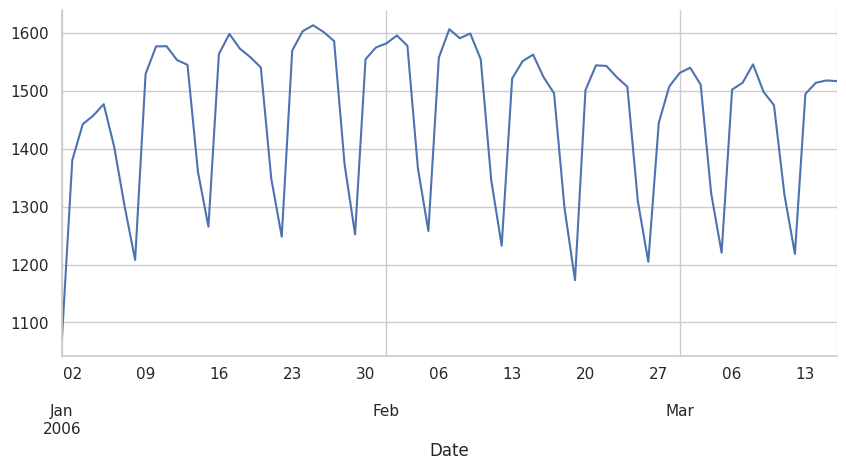

In [19]:
url = 'https://raw.githubusercontent.com/jenfly/opsd/master/opsd_germany_daily.csv'
data = pd.read_csv(url, sep=",")
data['Date'] = pd.to_datetime(data['Date'])
data = data.set_index('Date')
data['Consumption'].iloc[:75].plot();

In [20]:
tscv = TimeSeriesSplit(n_splits=3)

for train_index, test_index in tscv.split(data):
    print("TRAIN:", train_index, "TEST:", test_index)
    train_data = data.iloc[train_index]

TRAIN: [   0    1    2 ... 1095 1096 1097] TEST: [1098 1099 1100 ... 2190 2191 2192]
TRAIN: [   0    1    2 ... 2190 2191 2192] TEST: [2193 2194 2195 ... 3285 3286 3287]
TRAIN: [   0    1    2 ... 3285 3286 3287] TEST: [3288 3289 3290 ... 4380 4381 4382]


### Статистическое сравнение качества на кросс-валидации

#### Сначала формулируем вопрос

Вопрос - различается ли средний ROC AUC двух заранее заданных процедур на сопоставимых новых данных при допущениях нашего CV-эксперимента?

Сравниваем две логистические регрессии:
- A: `C=0.1`;
- B: `C=10.0`.

Остальная процедура одинаковая. Основная метрика — ROC AUC. Используем 5 фолдов и 10 повторений.

До расчета задаём двустороннюю гипотезу (обе модели на одном разбиении могут одновременно выиграть от удачного состава validation или одновременно столкнуться с трудными объектами), уровень 0.05 и учебную границу практически интересного эффекта 0.002 AUC

In [21]:
comparison_alpha = 0.05
practical_auc_difference = 0.002
comparison_n_splits = 5
comparison_n_repeats = 10

model_a = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(C=0.1, solver="liblinear", max_iter=3000, random_state=RANDOM_STATE))])
model_b = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(C=10.0, solver="liblinear", max_iter=3000, random_state=RANDOM_STATE))])
comparison_cv = RepeatedStratifiedKFold(n_splits=comparison_n_splits, n_repeats=comparison_n_repeats, random_state=RANDOM_STATE)
comparison_splits = list(comparison_cv.split(X_dev, y_dev))

comparison_scores_a = cross_val_score(model_a, X_dev, y_dev, cv=comparison_splits, scoring="roc_auc", n_jobs=N_JOBS, error_score="raise")
comparison_scores_b = cross_val_score(model_b, X_dev, y_dev, cv=comparison_splits, scoring="roc_auc", n_jobs=N_JOBS, error_score="raise")
comparison_differences = comparison_scores_b - comparison_scores_a

comparison_results = pd.DataFrame({
    "split": np.arange(len(comparison_splits)) + 1,
    "repeat": np.repeat(np.arange(1, comparison_n_repeats + 1), comparison_n_splits),
    "fold": np.tile(np.arange(1, comparison_n_splits + 1), comparison_n_repeats),
    "auc_a": comparison_scores_a,
    "auc_b": comparison_scores_b,
    "difference_b_minus_a": comparison_differences,
})
comparison_results.head(10)

,split,repeat,fold,auc_a,auc_b,difference_b_minus_a
0,1,1,1,0.9959,0.9938,-0.0021
1,2,1,2,0.9990,0.9964,-0.0026
2,3,1,3,0.9995,0.9979,-0.0015
3,4,1,4,0.9840,0.9871,0.0031
4,5,1,5,0.9959,0.9969,0.0010
5,6,2,1,0.9850,0.9794,-0.0057
6,7,2,2,1.0000,1.0000,0.0000
7,8,2,3,1.0000,1.0000,0.0000
8,9,2,4,0.9974,0.9923,-0.0052
9,10,2,5,0.9902,0.9959,0.0057


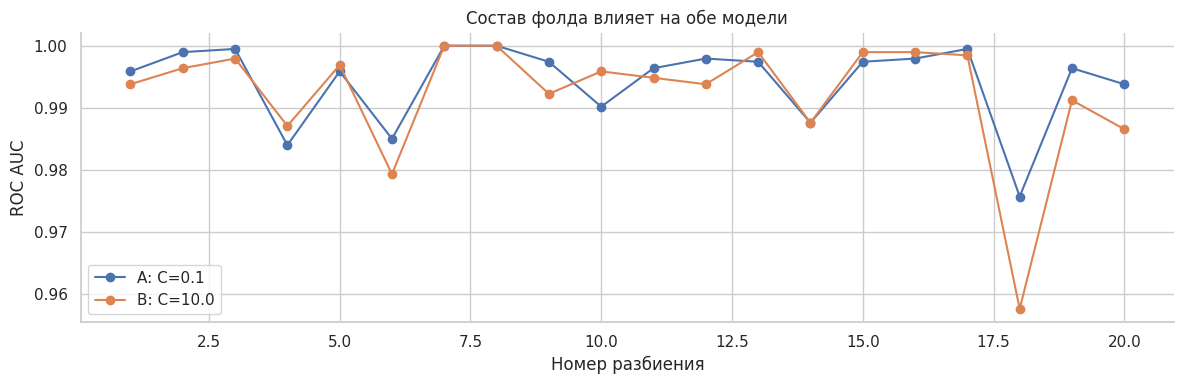

In [22]:
figure = plt.figure(figsize=(12, 4))
axis = figure.add_subplot(111)
axis.plot(comparison_results["split"].iloc[:20], comparison_results["auc_a"].iloc[:20], marker="o", label="A: C=0.1")
axis.plot(comparison_results["split"].iloc[:20], comparison_results["auc_b"].iloc[:20], marker="o", label="B: C=10.0")
axis.set(title="Состав фолда влияет на обе модели", xlabel="Номер разбиения", ylabel="ROC AUC")
axis.legend()
plt.tight_layout()
plt.show()

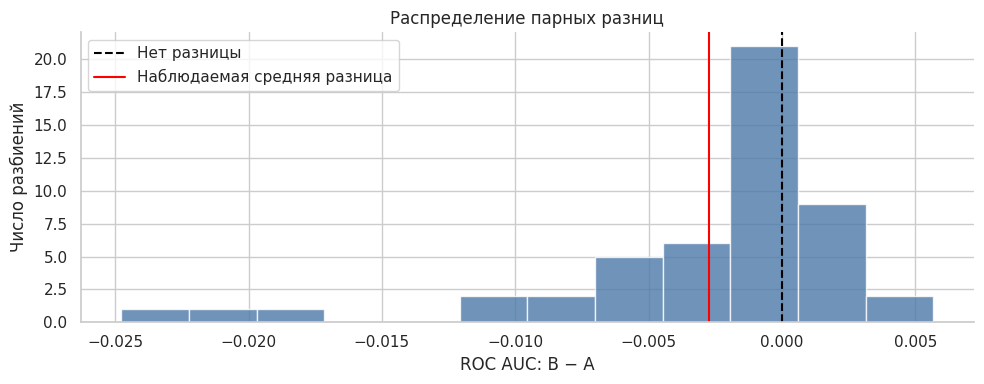

In [23]:
figure = plt.figure(figsize=(10, 4))
axis = figure.add_subplot(111)
axis.hist(comparison_differences, bins=12, color="#4C78A8", alpha=0.8, edgecolor="white")
axis.axvline(0, color="black", linestyle="--", label="Нет разницы")
axis.axvline(comparison_differences.mean(), color="red", label="Наблюдаемая средняя разница")
axis.set(title="Распределение парных разниц", xlabel="ROC AUC: B − A", ylabel="Число разбиений")
axis.legend()
plt.tight_layout()
plt.show()

### Наивный t-test и приближённая поправка на зависимость

Обозначим разницу на разбиении через $d_i$, число разбиений через $m$, выборочную дисперсию разниц через $s_d^2$.

При предположении независимости стандартная ошибка была бы:

$SE_{naive}=\sqrt{\frac{s_d^2}{m}}$

Но train-фолды пересекаются, а в repeated CV одни и те же объекты многократно участвуют в обучении и проверке. Обычный парный t-test не учитывает эту зависимость.

Для демонстрации используем приближённую поправку Nadeau–Bengio, как в официальном примере sklearn:

$SE_{corrected}=\sqrt{\left(\frac{1}{m}+\frac{n_{valid}}{n_{train}}\right)s_d^2}$

Далее строим t-статистику и рабочий 95% интервал с $m-1$ степенями свободы.

Нулевая гипотеза: средняя разница равна нулю. Альтернатива двусторонняя.


In [24]:
n_comparison_splits = len(comparison_differences)
comparison_degrees_of_freedom = n_comparison_splits - 1
mean_auc_difference = comparison_differences.mean()
auc_difference_variance = comparison_differences.var(ddof=1)
mean_validation_train_ratio = np.mean([len(split[1]) / len(split[0]) for split in comparison_splits])
naive_standard_error = np.sqrt(auc_difference_variance / n_comparison_splits)
corrected_standard_error = np.sqrt((1 / n_comparison_splits + mean_validation_train_ratio) * auc_difference_variance)
comparison_critical_value = stats.t.ppf(1 - comparison_alpha / 2, df=comparison_degrees_of_freedom)

naive_test_statistic = mean_auc_difference / naive_standard_error
corrected_test_statistic = mean_auc_difference / corrected_standard_error
naive_p_value = 2 * stats.t.sf(np.abs(naive_test_statistic), df=comparison_degrees_of_freedom)
corrected_p_value = 2 * stats.t.sf(np.abs(corrected_test_statistic), df=comparison_degrees_of_freedom)
naive_interval_low = mean_auc_difference - comparison_critical_value * naive_standard_error
naive_interval_high = mean_auc_difference + comparison_critical_value * naive_standard_error
corrected_interval_low = mean_auc_difference - comparison_critical_value * corrected_standard_error
corrected_interval_high = mean_auc_difference + comparison_critical_value * corrected_standard_error

comparison_inference = pd.DataFrame({
    "method": ["Наивный: зависимость проигнорирована", "Поправка Nadeau–Bengio: приближение"],
    "mean_auc_a": comparison_scores_a.mean(),
    "mean_auc_b": comparison_scores_b.mean(),
    "mean_difference_b_minus_a": mean_auc_difference,
    "standard_error": [naive_standard_error, corrected_standard_error],
    "interval_95_low": [naive_interval_low, corrected_interval_low],
    "interval_95_high": [naive_interval_high, corrected_interval_high],
    "two_sided_p_value": [naive_p_value, corrected_p_value],
})
comparison_inference

,method,mean_auc_a,mean_auc_b,mean_difference_b_minus_a,standard_error,interval_95_low,interval_95_high,two_sided_p_value
0,Наивный: зависимость проигнорирована,0.9939,0.9912,-0.0027,0.0008,-0.0044,-0.0011,0.0019
1,Поправка Nadeau–Bengio: приближение,0.9939,0.9912,-0.0027,0.0031,-0.0089,0.0034,0.3753


#### Интервал эффекта

- Положительная разница означает преимущество B, отрицательная — A.
- Пересечение нуля означает, что выбранная приближённая двусторонняя проверка не обнаруживает отличия при данном уровне.
- Необнаружение отличия не доказывает равенство моделей!
- Малый p-value не означает большой или полезный эффект.

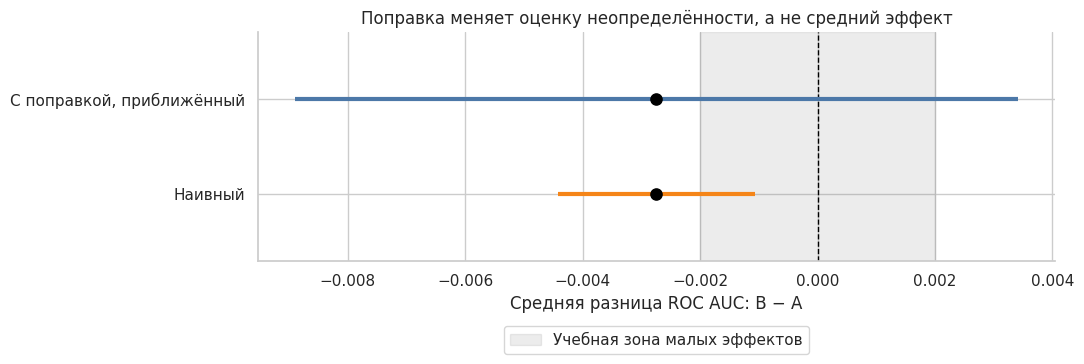

In [25]:
figure = plt.figure(figsize=(11, 4))
axis = figure.add_subplot(111)
axis.axvspan(-practical_auc_difference, practical_auc_difference, color="gray", alpha=0.15, label="Учебная зона малых эффектов")
axis.axvline(0, color="black", linestyle="--", linewidth=1)

for method_index in range(len(comparison_inference)):
    method_row = comparison_inference.iloc[method_index]
    axis.hlines(method_index, method_row["interval_95_low"], method_row["interval_95_high"], linewidth=3, color=["#F58518", "#4C78A8"][method_index])
    axis.scatter(method_row["mean_difference_b_minus_a"], method_index, s=65, color="black", zorder=3)

axis.set_yticks(np.arange(len(comparison_inference)))
axis.set_yticklabels(["Наивный", "С поправкой, приближённый"])
axis.set(title="Поправка меняет оценку неопределённости, а не средний эффект", xlabel="Средняя разница ROC AUC: B − A")
axis.set_ylim(-0.7, 1.7)
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()

In [26]:
comparison_interpretation = pd.Series({
    "Наблюдаемая разница B − A": mean_auc_difference,
    "Поправка увеличила SE во столько раз": corrected_standard_error / naive_standard_error,
    "Интервал содержит ноль": corrected_interval_low <= 0 <= corrected_interval_high,
    "p < alpha в приближённом тесте": corrected_p_value < comparison_alpha,
    "Интервал включает улучшение B не меньше delta": corrected_interval_high >= practical_auc_difference,
    "Интервал включает ухудшение B не меньше delta": corrected_interval_low <= -practical_auc_difference,
  }, name="Интерпретация, а не только p-value")
comparison_interpretation

,"Интерпретация, а не только p-value"
Наблюдаемая разница B − A,-0.0027
Поправка увеличила SE во столько раз,3.6742
Интервал содержит ноль,True
p < alpha в приближённом тесте,False
Интервал включает улучшение B не меньше delta,True
Интервал включает ухудшение B не меньше delta,True
